# <a href="https://thetahat.ru/courses/ad">Введение в анализ данных</a>
## Домашнее задание 9. Условные распределения


**Правила, <font color="red">прочитайте внимательно</font>:**

1. Общее

     * Выполненную работу **в формате `ipynb`** нужно отправить по ссылке "Сдача ДЗ" на <a href="https://thetahat.ru/courses/ad"><b>странице курса</b></a>. **Работы, присланные иным способом, не принимаются.** Дедлайны указаны в боте и на сайте, они являются строгими.
     
     * Обязательно изучите <a href="https://thetahat.ru/courses/design-hw"><b>руководство по оформлению ДЗ</b></a>. В частности, оно содержит примеры случаев, когда могут быть снижены баллы.
     
     * Обратите внимание на <a href="https://thetahat.ru/courses/ai-rules"><b>правила использования ИИ-инструментов</b></a> при решении домашнего задания.
     
     * Выполнять задание необходимо полностью самостоятельно. **При обнаружении списывания (в т.ч. злоупотребление ИИ) всем участникам списывания дается штраф -3 скор-балла к итоговой оценке.**
     
     * Решение теоретических задач оформляйте в markdown-ячейках формате $\LaTeX$. При решении можно использовать ИИ-инструменты только для оформления написанного самостоятельно решения. Например, написать черновик формул и попросить ИИ оформить эти формулы в $\LaTeX$.
     
     * Решение проверяется системой ИИ-проверки <a href="https://thetahat.ru/"><img src="https://miptstats.github.io/theta_grader_small.png" style="display: inline; vertical-align: middle;"></a> **ThetaGrader**. Результат проверки валидируется и исправляется человеком, после чего комментарии отправляются студентам.
     </br>

2. Правила заполнения ноутбука

     * Запрещается удалять имеющиеся в ноутбуке ячейки, менять местами положения существующих ячеек.
     * Отвечайте на вопросы, а также добавляйте новые ячейки в любом количестве в предложенных местах, которые обозначены `<...>`.
     * Сохраняйте естественный линейный порядок повествования в ноутбуке сверху-вниз. Комментарии к решению пишите в markdown-ячейках.
     * Условия <font color="red"><b>запрещается модифицировать</b></font>.
     * При нарушении данных правил работа может получить 0 баллов.
</br>


**Баллы за задание**

* Задача 1 &mdash; 40 баллов
* Задача 2 &mdash; 50 баллов
* Задача 2 &mdash; 40 баллов

In [ ]:
# Bot check

# HW_ID: fpmi_ad9
# Бот проверит этот ID и предупредит, если случайно сдать что-то не то.

# Status: final
# Перед отправкой в финальном решении удали "not" в строчке выше.
# Так бот проверит, что ты отправляешь финальную версию, а не промежуточную.
# Никакие значения в этой ячейке не влияют на факт сдачи работы.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from numpy.linalg import lstsq
from sklearn.datasets import load_breast_cancer

### Ссылки на использование ИИ

Если при решении задач использовался ИИ, укажи здесь публичные ссылки на все чаты с ИИ и поясни, для каких целей он применялся. Обрати внимание на <a href="https://thetahat.ru/courses/ai-rules" target="_top">правила</a>.

**Задача 1,2**
1. использовала код с лекции

**Задача 3**
1. https://chat.deepseek.com/share/urog8iem2165zjeus1
    - оформление формул; спрашивала про методы и их синтаксис

---
### Задача 1.


Рассмотрим датасет Breast Cancer Wisconsin Diagnostic. Это медицинский датасет про диагностику рака молочной железы. Он был собран в начале 1990-х годов в University of Wisconsin Hospitals: пациенткам с подозрительными уплотнениями в груди проводилась тонкоигольная аспирационная биопсия (FNA), полученный материал фотографировался под микроскопом, и с оцифрованных изображений автоматически выделялись границы клеточных ядер, по ним вычислялись геометрические характеристики. Итоговая версия содержит 569 образцов (212 злокачественных, 357 доброкачественных) и 30 числовых признаков.

Каждое наблюдение — это один опухолевый образец. Для каждого ядра клетки на снимке измеряются 10 базовых характеристик, а затем по всем ядрам образца считаются три агрегата: 
* среднее (`mean`), 
* «худшее»/максимальное из трёх наибольших значений (`worst`),
* стандартная ошибка (`error`). 

Так получаются 30 признаков. Рассмотрим три из них:
* `mean area` — средняя площадь ядра;
* `mean radius` — средний радиус ядра клетки, то есть среднее расстояние от центра ядра до точек на его границе (в пикселях);
* `mean concavity` — средняя выраженность вогнутых участков контура ядра (насколько глубоко граница «заходит внутрь»);

Загрузим данные

In [2]:
df = load_breast_cancer(as_frame=True).frame
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
features = ["mean area", "mean radius", "mean concavity"]
X = df[features].copy()
X.head()

,mean area,mean radius,mean concavity
0,1001.0,17.99,0.3001
1,1326.0,20.57,0.0869
2,1203.0,19.69,0.1974
3,386.1,11.42,0.2414
4,1297.0,20.29,0.1980


Исследуйте корреляцию между всеми парами рассматриваемых трех признаков.

In [4]:
corr = X.corr()
corr

,mean area,mean radius,mean concavity
mean area,1.000000,0.987357,0.685983
mean radius,0.987357,1.000000,0.676764
mean concavity,0.685983,0.676764,1.000000


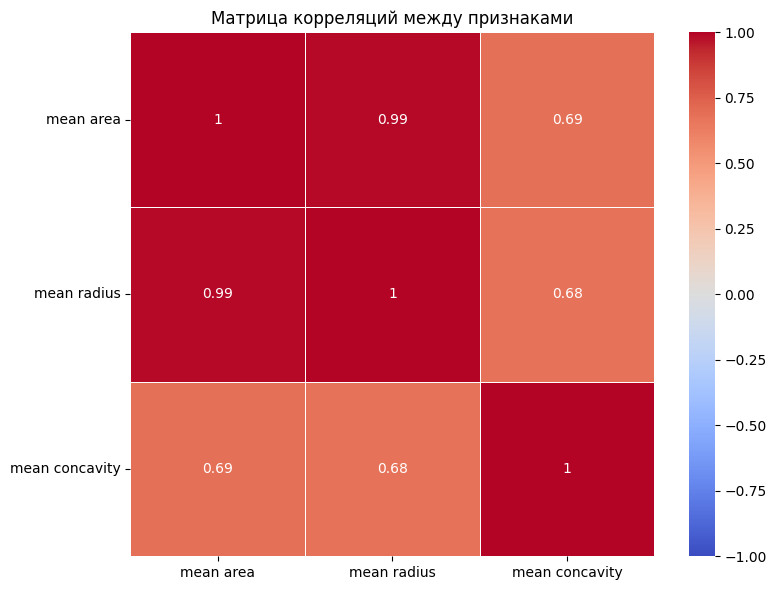

In [5]:
plt.figure(figsize=(8, 6))
sns.heatmap(X.corr(),
            annot=True,
            cmap='coolwarm',
            vmin=-1, vmax=1,
            square=True,
            linewidths=0.5)
plt.title("Матрица корреляций между признаками")
plt.xticks(ticks=np.arange(len(features)) + 0.5,
           labels=features, 
           ha='center')
plt.yticks(ticks=np.arange(len(features)) + 0.5,
           labels=features,
           rotation=0,
           va='center')
plt.tight_layout()
plt.show()

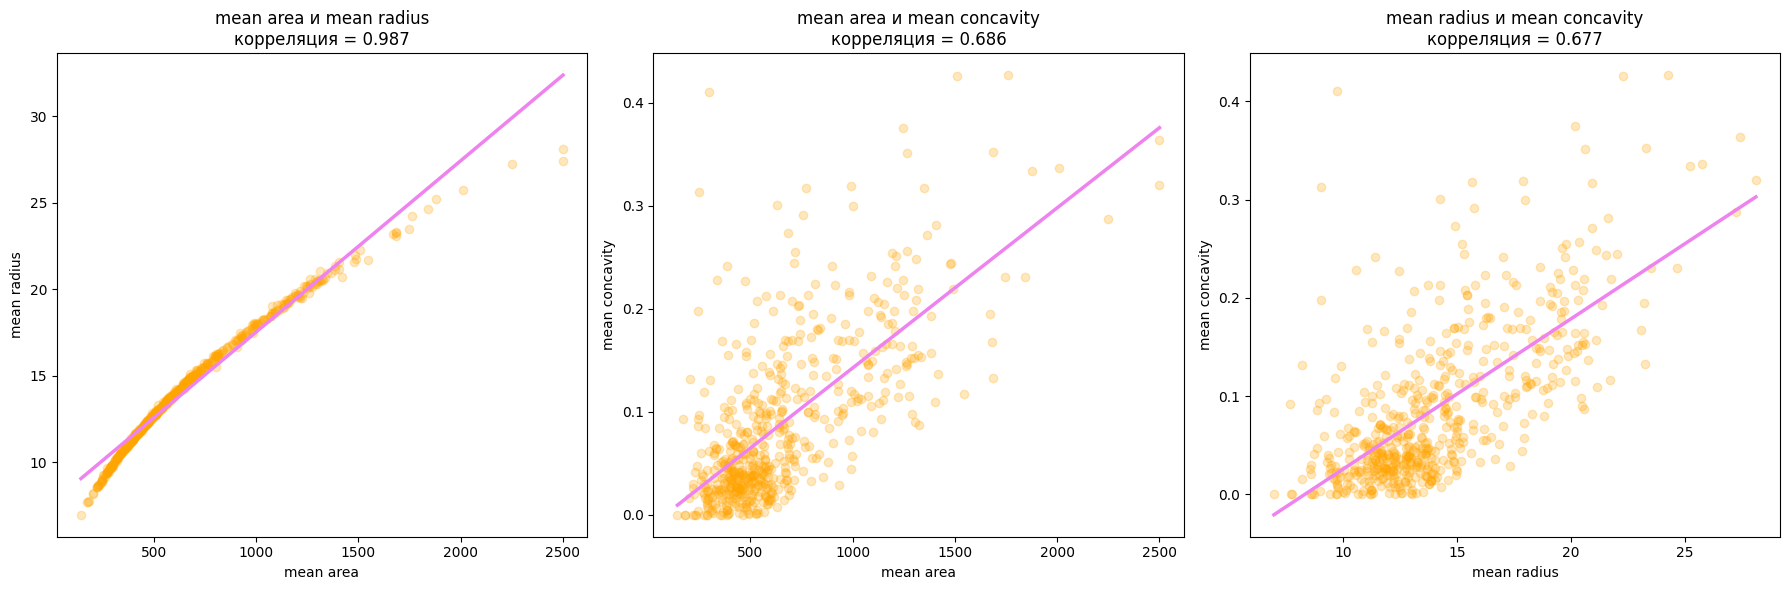

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

pairs = [
    ("mean area", "mean radius"),
    ("mean area", "mean concavity"),
    ("mean radius", "mean concavity"),
]

for ax, (x_label, y_label) in zip(axes, pairs):
    x_vals = X[x_label]
    y_vals = X[y_label]
    r = np.corrcoef(x_vals, y_vals)[0, 1]
    
    ax.scatter(x_vals, y_vals, alpha=0.25, color="orange")
    
    m, b = np.polyfit(x_vals, y_vals, 1)
    xr = np.linspace(x_vals.min(), x_vals.max(), 200)
    yr = m * xr + b
    ax.plot(xr, yr, linewidth=2.5, color="violet")
    
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_title(f"{x_label} и {y_label}\nкорреляция = {r:.3f}")

plt.tight_layout()
plt.show()

**Вывод по корреляции:**
- `mean area` и `mean radius` очень сильно положительно коррелированы (0.987);

- `mean area` и `mean concavity` умеренная положительная корреляция (0.686);

- `mean radius` и `mean concavity` умеренная положительная корреляция (0.677);

- Все три признака зависимы, но связь между площадью и радиусом (0.987) значительно сильнее, чем связь каждого из них с вогнутостью (0.68).

Теперь исследуйте частичную корреляцию для этих признаков

In [8]:
def partial_corr(df: pd.DataFrame, x: str, y: str, covars: list[str]) -> float:
    """
    Частичная корреляция между x и y при фиксированных ковариатах через остатки OLS.

    Аргументы:
        df: DataFrame с исходными данными.
        x: Название столбца первой переменной.
        y: Название столбца второй переменной.
        covars: Список названий столбцов фиксируемых ковариат.

    Возвращает:
        Значение частной корреляции между x и y.
    """

    X_cov = df[covars].astype(float).values
    X_cov = np.column_stack([np.ones(len(X_cov)), X_cov])

    def resid(v):
        beta, *_ = lstsq(X_cov, v, rcond=None)
        return v - X_cov @ beta

    rx = resid(df[x].astype(float).values)
    ry = resid(df[y].astype(float).values)
    return np.corrcoef(rx, ry)[0, 1]

In [9]:
pc_ar_concavity = partial_corr(X, "mean area", "mean radius", ["mean concavity"])
pc_ac_radius = partial_corr(X, "mean area", "mean concavity", ["mean radius"])
pc_rc_area = partial_corr(X, "mean radius", "mean concavity", ["mean area"])

print("partial corr(mean area, mean radius | mean concavity) =", round(pc_ar_concavity, 3))
print("partial corr(mean area, mean concavity | mean radius) =", round(pc_ac_radius, 3))
print("partial corr(mean radius, mean concavity | mean area) =", round(pc_rc_area, 3))

partial corr(mean area, mean radius | mean concavity) = 0.977
partial corr(mean area, mean concavity | mean radius) = 0.152
partial corr(mean radius, mean concavity | mean area) = -0.005


In [10]:
def residuals_on_covars(df: pd.DataFrame, y_col: str, covars: list[str]) -> np.ndarray:
    """Вычисляет остатки y после регрессии на X."""
    Z = df[covars].astype(float).values
    Z = np.column_stack([np.ones(len(Z)), Z])
    y = df[y_col].astype(float).values
    beta, *_ = lstsq(Z, y, rcond=None)
    return y - Z @ beta

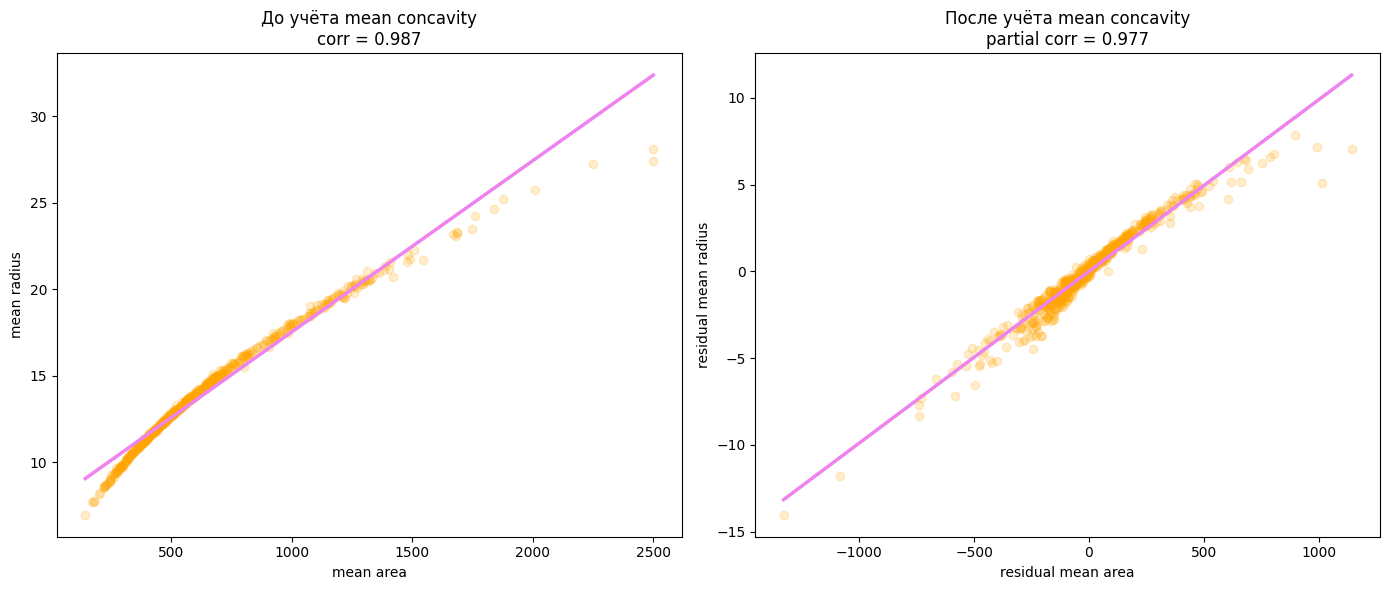

In [11]:
x_raw = X["mean area"].values
y_raw = X["mean radius"].values

x_res = residuals_on_covars(X, "mean area", ["mean concavity"])
y_res = residuals_on_covars(X, "mean radius", ["mean concavity"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# обычная корреляция
r_raw = np.corrcoef(x_raw, y_raw)[0, 1]
axes[0].scatter(x_raw, y_raw, alpha=0.2, color="orange")
m, b = np.polyfit(x_raw, y_raw, 1)
xr = np.linspace(x_raw.min(), x_raw.max(), 200)
yr =  m * xr + b
axes[0].plot(xr, yr, linewidth=2.5, color="violet")
axes[0].set_title(f"До учëта mean concavity\ncorr = {r_raw:.3f}")
axes[0].set_xlabel("mean area")
axes[0].set_ylabel("mean radius")

# частичная корреляция
r_res = np.corrcoef(x_res, y_res)[0, 1]
axes[1].scatter(x_res, y_res, alpha=0.2, color="orange")
m, b = np.polyfit(x_res, y_res, 1)
xr = np.linspace(x_res.min(), x_res.max(), 200)
yr =  m * xr + b
axes[1].plot(xr, yr, linewidth=2.5, color="violet")
axes[1].set_title(f"После учëта mean concavity\npartial corr = {r_res:.3f}")
axes[1].set_xlabel("residual mean area")
axes[1].set_ylabel("residual mean radius")

plt.tight_layout()
plt.show()

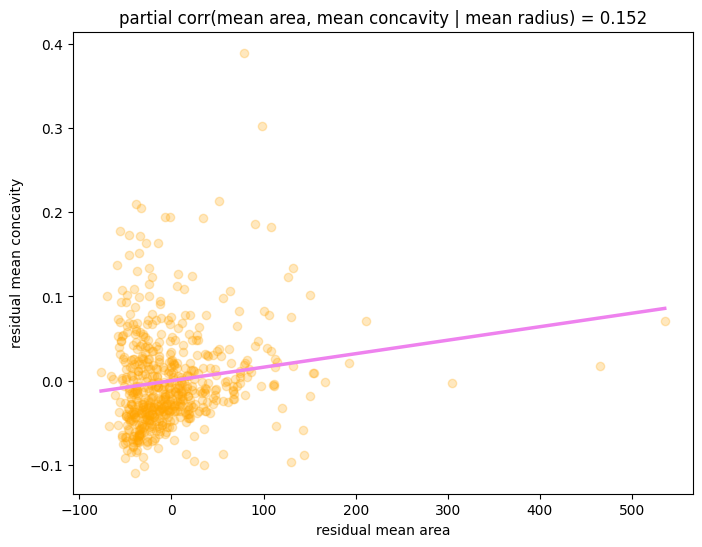

In [12]:
x_res = residuals_on_covars(X, "mean area", ["mean radius"])
y_res = residuals_on_covars(X, "mean concavity", ["mean radius"])

plt.figure(figsize=(8, 6))
r_res = np.corrcoef(x_res, y_res)[0,1]
plt.scatter(x_res, y_res, alpha=0.25, color="orange")
m, b = np.polyfit(x_res, y_res, 1)
xr = np.linspace(x_res.min(), x_res.max(), 200)
yr =  m * xr + b
plt.plot(xr, yr, linewidth=2.5, color="violet")
plt.title(f"partial corr(mean area, mean concavity | mean radius) = {r_res:.3f}")
plt.xlabel("residual mean area")
plt.ylabel("residual mean concavity")
plt.show()

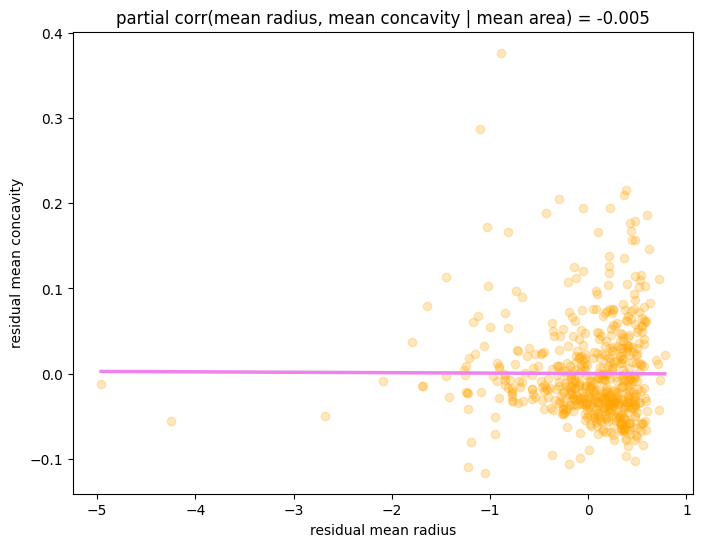

In [13]:
x_res = residuals_on_covars(X, "mean radius", ["mean area"])
y_res = residuals_on_covars(X, "mean concavity", ["mean area"])

plt.figure(figsize=(8, 6))
r_res = np.corrcoef(x_res, y_res)[0,1]
plt.scatter(x_res, y_res, alpha=0.25, color="orange")
m, b = np.polyfit(x_res, y_res, 1)
xr = np.linspace(x_res.min(), x_res.max(), 200)
yr =  m * xr + b
plt.plot(xr, yr, linewidth=2.5, color="violet")
plt.title(f"partial corr(mean radius, mean concavity | mean area) = {r_res:.3f}")
plt.xlabel("residual mean radius")
plt.ylabel("residual mean concavity")
plt.show()

Можете ли вы **только лишь по данным** установить, какой из признаков является причиной, а какой &mdash; следствием? Сможет ли это сделать только по этим данным сколько угодно умная нейросеть?

**Ответ: нет, нельзя.**

Ни человек, ни нейросеть не могут определить, какой признак — причина, а какой — следствие, только на основе наблюдаемых данных.

**Потому что:**

1. $\text{Корреляция} \neq \text{причинность}$

Мы вычислили обычные корреляции между признаками:
| Пара признаков | Коэффициент корреляции |
|----------------|------------------------|
| corr(mean area, mean radius) | 0.987 |
| corr(mean area, mean concavity) | 0.686 |
| corr(mean radius, mean concavity) | 0.677 |

**Проблема** в том, что одна и та же корреляция 0.987 между area и radius может означать:
- площадь влияет на радиус
- радиус влияет на площадь
- третья переменная влияет на оба

Данные не позволяют выбрать правильный вариант.

2. Частная корреляция не решает проблему

Мы вычислили частные корреляции, чтобы исключить влияние третьего признака:

| Пара признаков | Частная корреляция |
|----------------|-------------------|
| partial corr(mean area, mean radius \| mean concavity) | 0.977 |
| partial corr(mean area, mean concavity \| mean radius) | 0.152 |
| partial corr(mean radius, mean concavity \| mean area) | -0.005 |

**Проблема** в том, что даже после исключения влияния третьего признака
мы не можем определить, что является причиной — area или radius. 
Частная корреляция 0.977 между area и radius остаётся сильной, 
но направление причинности по-прежнему неизвестно.

3. Нейросеть тоже бессильна

Даже если умная нейросеть найдёт идеальную зависимость и будет очень точно 
предсказывать один признак по другому, она всё равно **не сможет определить, 
что является причиной, а что следствием**, потому что:
- нет информации о механизме генерации данных;
- нет эксперимента (нельзя случайным образом назначить причину);
- нет временного порядка (неизвестно, что появилось раньше).

Можете ли вы установить, какой из признаков является причиной, а какой &mdash; следствием, опираясь на свои представления о природе данных?

**Ответ: Да, можно**

Опираясь на **представления о природе данных** (а не только на сами данные), 
можно обоснованно определить, какой признак является причиной, 
а какой — следствием.

**Потому что:**
1. Геометрическая природа признаков

Из геометрии известно, что для круга (или эллипса) справедлива формула:
$$S = \pi \cdot R^2$$
где:
- $S$ — площадь ядра (`mean area`)
- $R$ — радиус ядра (`mean radius`)

Это означает, что **радиус является определяющим признаком**, 
а площадь — **следствием**. 
Изменить площадь, не меняя радиус, невозможно.

2. Направление зависимости

| Признак | Роль | Обоснование |
|---------|------|-------------|
| `mean radius` | **Причина** | Радиус — первичная геометрическая характеристика |
| `mean area` | **Следствие** | Площадь вычисляется через радиус: $S = \pi R^2$ |
| `mean concavity` | **Независимый признак** | Вогнутость не связана с размером (частная корреляция близка к 0) |

3. Подтверждение из частной корреляции

Из частичных корреляций видно:

| Пара признаков | Частная корреляция | Интерпретация |
|----------------|-------------------|---------------|
| partial corr(area, radius \| concavity) | 0.977 | Связь сильная, но направление известно из геометрии |
| partial corr(area, concavity \| radius) | 0.152 | Слабая связь — исчезает при контроле радиуса |
| partial corr(radius, concavity \| area) | -0.005 | Нет связи — вогнутость не зависит от размера |

**Что показывают эти числа:**
- Связь `area` $\leftrightarrow$ `concavity` и `radius` $\leftrightarrow$ `concavity` — **ложные**.
- Вогнутость не зависит от размера ядра.

4. Почему нейросеть не смогла бы это определить

Нейросеть видит только числовые значения `mean area` или `mean radius`.
Она не знает формулу $S = \pi R^2$, потому что это знание о **природе данных**, 
а не о самих данных.

Человек, в отличие от нейросети, может привлечь внешнее знание:
- геометрические законы;
- физический смысл признаков;
- причинные механизмы генерации данных.

**Вывод:** Опираясь на представления о природе данных (геометрию, физику), 
мы можем установить, что **радиус является причиной, а площадь — следствием**. 
Нейросеть без этих знаний этого сделать не сможет.

Выводы:

В ходе анализа трёх признаков датасета (`mean area`, `mean radius`, `mean concavity`) были получены результаты:

1. **Обычные корреляции** показали сильную связь между `mean area` и `mean radius` (0.987) 
   и умеренные связи этих признаков с `mean concavity` (0.686 и 0.677).

2. **Частные корреляции** выявили, что связи с `mean concavity` являются ложными — 
   они исчезают при контроле размера ядра (0.152 и -0.005). Связь между 
   `mean area` и `mean radius` остаётся высокой (0.977).

3. **Только по данным** установить причинно-следственные связи невозможно, 
   так как корреляция не равна причинности. Нейросеть тоже не справится.

4. **Опираясь на геометрическую природу** признаков ($S = \pi R^2$), 
   можно обоснованно утверждать, что `mean radius` — причина, `mean area` — следствие. 
   `mean concavity` — независимый признак формы.

**Главный вывод:** Размер ядра (радиус/площадь) — ключевая характеристика. 
Вогнутость не даёт дополнительной информации о размере.


---
### Задача 2.

**1.** Пусть $X$ и $Y$ — случайные величины, причём $\mathsf{E} Y^2 < \infty$. Докажите формулу полной дисперсии
$$\mathsf{D} Y \;=\; \mathsf{E}\big[\mathsf{D}(Y\,|\,X)\big] \;+\; \mathsf{D}\big[\mathsf{E}(Y\,|\,X)\big].$$

<details>
<summary> ➡️ Если в твоем курсе теории вероятностей еще не было условных мат. ожиданий, кликни сюда </summary>
Тебе могут помочь следующие формулы:
    
1. Условная дисперсия определяется через условные математические ожидания $$\mathsf{D}(Y\mid X) = \mathsf{E}(Y^2\mid X) - \big[\mathsf{E}(Y\mid X)\big]^2.$$
    
2. Усреднение условного математического ожидания дает обычное математическое ожидание $$\mathsf{E}\big[\mathsf{E}(Y\mid X)\big] = \mathsf{E}Y.$$
</details>

### Доказательство формулы полной дисперсии

Покажем, что

$$
\mathbb{Var}(Y) = \mathbb{E}[\mathbb{Var}(Y \mid X)] + \mathbb{Var}[\mathbb{E}(Y \mid X)].
$$

Начнём с определения дисперсии:

$$
\mathbb{Var}(Y) = \mathbb{E}(Y^2) - (\mathbb{E}Y)^2.
$$

Теперь распишем оба слагаемых через условное математическое ожидание:

$$
\mathbb{E}(Y^2) = \mathbb{E}\big(\mathbb{E}(Y^2 \mid X)\big),
$$

$$
\mathbb{E}Y = \mathbb{E}\big(\mathbb{E}(Y \mid X)\big).
$$

Тогда

$$
\mathbb{Var}(Y) = \mathbb{E}\big(\mathbb{E}(Y^2 \mid X)\big) - \Big(\mathbb{E}\big(\mathbb{E}(Y \mid X)\big)\Big)^2.
$$

Добавим и вычтем величину

$$
\mathbb{E}\big((\mathbb{E}(Y \mid X))^2\big).
$$

Получим:

$$
\mathbb{Var}(Y)=
\mathbb{E}\big(\mathbb{E}(Y^2 \mid X)\big)
- \mathbb{E}\big((\mathbb{E}(Y \mid X))^2\big)
+ \mathbb{E}\big((\mathbb{E}(Y \mid X))^2\big)
- \Big(\mathbb{E}\big(\mathbb{E}(Y \mid X)\big)\Big)^2.
$$

Сгруппируем слагаемые:

$$
\mathbb{Var}(Y)=
\mathbb{E}\Big(\mathbb{E}(Y^2 \mid X) - (\mathbb{E}(Y \mid X))^2\Big)
+
\Big(
\mathbb{E}\big((\mathbb{E}(Y \mid X))^2\big)
-
\big(\mathbb{E}(\mathbb{E}(Y \mid X))\big)^2
\Big).
$$

Но по определению условной дисперсии:

$$
\mathbb{Var}(Y \mid X) = \mathbb{E}(Y^2 \mid X) - (\mathbb{E}(Y \mid X))^2,
$$

а второе выражение есть дисперсия условного математического ожидания:

$$
\mathbb{Var}(\mathbb{E}(Y \mid X))=
\mathbb{E}\big((\mathbb{E}(Y \mid X))^2\big)
-
\big(\mathbb{E}(\mathbb{E}(Y \mid X))\big)^2.
$$

Следовательно,

$$
\boxed{
\mathbb{Var}(Y)=\mathbb{E}[\mathbb{Var}(Y \mid X)] + \mathbb{Var}[\mathbb{E}(Y \mid X)]
}
$$

что и требовалось доказать.

Пусть $X$ — это признаки группы (возраст, регион, профессия и т. п.), а $Y$ — измеряемая характеристика (таргет) внутри группы. Подробно проинтерпретируйте каждое слагаемое формулы.

### Интерпретация формулы полной дисперсии

Формула
$$
\mathbb{Var}(Y)=\mathbb{E}[\mathbb{Var}(Y \mid X)] + \mathbb{Var}[\mathbb{E}(Y \mid X)]
$$

разбивает общую дисперсию таргета на две части.

---

### 1. $\mathbb{E}[\mathbb{Var}(Y \mid X)]$ — внутригрупповая дисперсия

Это средняя (по всем группам) дисперсия таргета внутри групп с одинаковыми значениями $X$.

Смысл:
- показывает разброс $Y$ среди объектов с одинаковыми признаками;
- отражает **необъяснённую часть вариативности**;
- соответствует шуму и индивидуальным различиям.

Пример: Люди одного возраста, одного региона и одной профессии всё равно имеют разный доход  — это и есть внутригрупповая дисперсия.

---

### 2. $\mathbb{Var}(\mathbb{E}[Y \mid X])$ — межгрупповая дисперсия

Это дисперсия средних значений таргета в разных группах.

Смысл:
- показывает, насколько отличаются средние значения $Y$ при разных $X$;
- отражает **объяснённую признаками часть вариативности**;
- характеризует влияние признаков $X$ на таргет $Y$.

Пример: Средний доход в группе "25 лет, Москва, IT" отличается от среднего дохода в группе "50 лет, пригород, учитель".

---

### Общий смысл

Общая дисперсия раскладывается на:

$$
\text{общая дисперсия}
=
\text{необъяснённая (внутри групп)}
+
\text{объяснённая (между группами)}.
$$

Чем больше объяснённая часть, тем сильнее признаки $X$ влияют на $Y$.

**2.** На лекции был показан способ эмпирической оценки условного математического ожидания. Для тех же синтетических данных с лекции посчитайте приближенно 
* условную дисперсию и отобразите ее на графике (анимацию делать не нужно),
* все компоненты формулы полной дисперсии.

Подтвердилась ли формула?

**Ответ:** Да, подтвердилась.

In [14]:
np.random.seed(42)

def generate_data(n_samples: int = 500) -> tuple[np.ndarray, np.ndarray]:
    """
    Генерирует данные со сложной нелинейной зависимостью Y от X.

    Аргументы:
        n_samples: Количество генерируемых точек.

    Возвращает:
        Кортеж (X, Y) из отсортированных массивов признака и целевой переменной.
    """
    X = np.random.rand(n_samples) * 10

    true_mean_func = lambda x: 2 * np.sin(x) + 0.1 * x**2
    noise_std = 0.5 + 2 * np.sin(np.pi * X / 10)

    Y = true_mean_func(X) + np.random.randn(n_samples) * noise_std

    bifurcation_mask = (X > 6) & (X < 8)
    bifurcation_indices = np.where(bifurcation_mask)[0]
    switch = np.random.rand(len(bifurcation_indices)) > 0.5

    Y[bifurcation_indices[switch]] += 5 * (1 - np.abs(X[bifurcation_indices[switch]] - 7) ** 2)
    Y[bifurcation_indices[~switch]] -= 5 * (1 - np.abs(X[bifurcation_indices[~switch]] - 7) ** 2)

    sorted_indices = np.argsort(X)
    return X[sorted_indices], Y[sorted_indices]

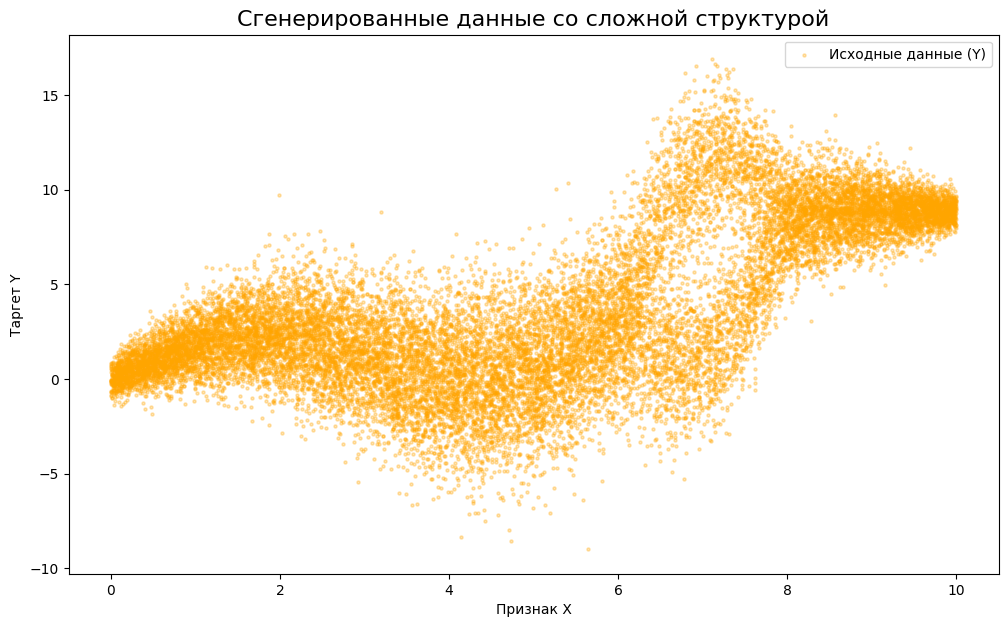

In [15]:
X, Y = generate_data(n_samples=20000)

plt.figure(figsize=(12, 7))
plt.scatter(X, Y, alpha=0.3, s=5, color="orange", label="Исходные данные (Y)")
plt.xlabel("Признак X")
plt.ylabel("Таргет Y")
plt.title("Сгенерированные данные со сложной структурой", fontsize=16)
plt.legend()
plt.show()

### Оценка $\mathbb{E}(Y|X)$ с помощью локального усреднения

In [16]:
def gaussian_kernel(u: np.ndarray) -> np.ndarray:
    """
    Вычисляет значение гауссовское ядро.

    Аргументы:
        u: Массив нормированных расстояний до целевой точки.

    Возвращает:
        Массив значений гауссова ядра в точках u.
    """
    return np.exp(-0.5 * u**2)

def gaussian_kernel_regression(
    x_target: float, X_train: np.ndarray, Y_train: np.ndarray, h: float
) -> float:
    """
    Вычисляет оценку регрессии в точке с помощью гауссовского ядра.

    Аргументы:
        x_target: Точка, в которой вычисляется оценка регрессии.
        X_train: Массив значений признака обучающей выборки.
        Y_train: Массив значений целевой переменной обучающей выборки.
        h: Ширина окна ядра.

    Возвращает:
        Взвешенную оценку условного математического ожидания в точке x_target или NaN,
        если сумма весов равна нулю.
    """
    dists = X_train - x_target
    weights = gaussian_kernel(dists / h)

    if np.sum(weights) == 0:
        return np.nan

    return np.sum(weights * Y_train) / np.sum(weights)

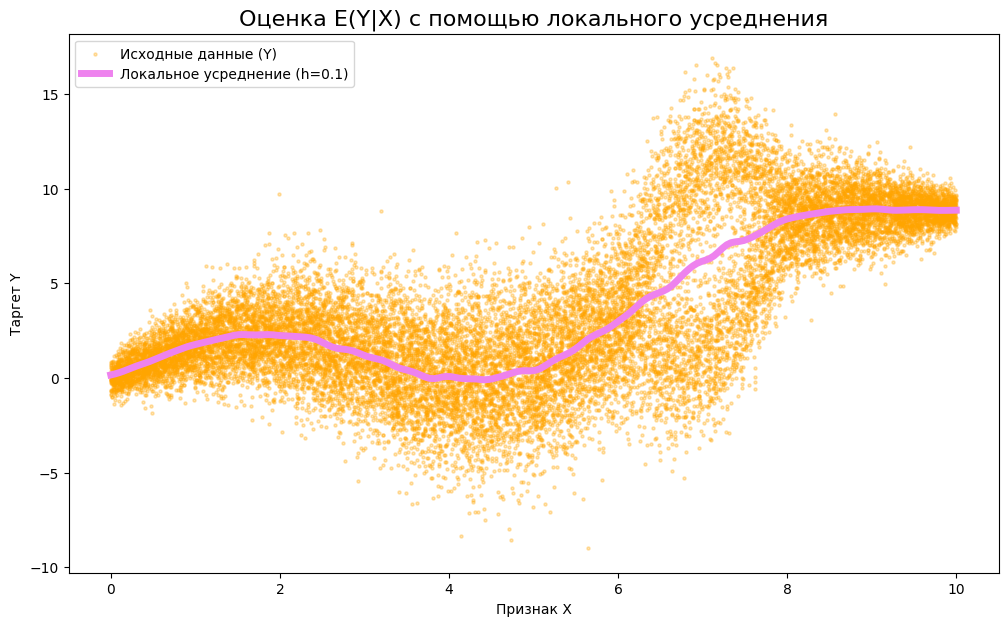

In [17]:
h = 0.1
x_grid = np.linspace(X.min(), X.max(), 200)
y_pred = np.array([gaussian_kernel_regression(xt, X, Y, h) for xt in x_grid])

plt.figure(figsize=(12, 7))
plt.scatter(X, Y, alpha=0.3, s=5, color="orange", label="Исходные данные (Y)")
plt.plot(x_grid, y_pred, color="violet", linewidth=5, label=f"Локальное усреднение (h={h})")
plt.xlabel("Признак X")
plt.ylabel("Таргет Y")
plt.title("Оценка E(Y|X) с помощью локального усреднения", fontsize=16)
plt.legend()
plt.show()

### Оценка условной дисперсии

Используем тождество:

$$
\mathbb{Var}(Y \mid X = x) = \mathbb{E}(Y^2 \mid X = x) - \bigl(\mathbb{E}(Y \mid X = x)\bigr)^2.
$$

То есть отдельно оцениваем:

$$
\mathbb{E}(Y \mid X = x), \quad \mathbb{E}(Y^2 \mid X = x).
$$

In [18]:
# Оценка E(Y | X = x)
y_pred = np.array([gaussian_kernel_regression(xt, X, Y, h) for xt in x_grid])

# Оценка E(Y^2 | X = x)
y2_pred = np.array([gaussian_kernel_regression(xt, X, Y**2, h) for xt in x_grid])

# Оценка условной дисперсии
var_pred = np.maximum(y2_pred - y_pred**2, 0)

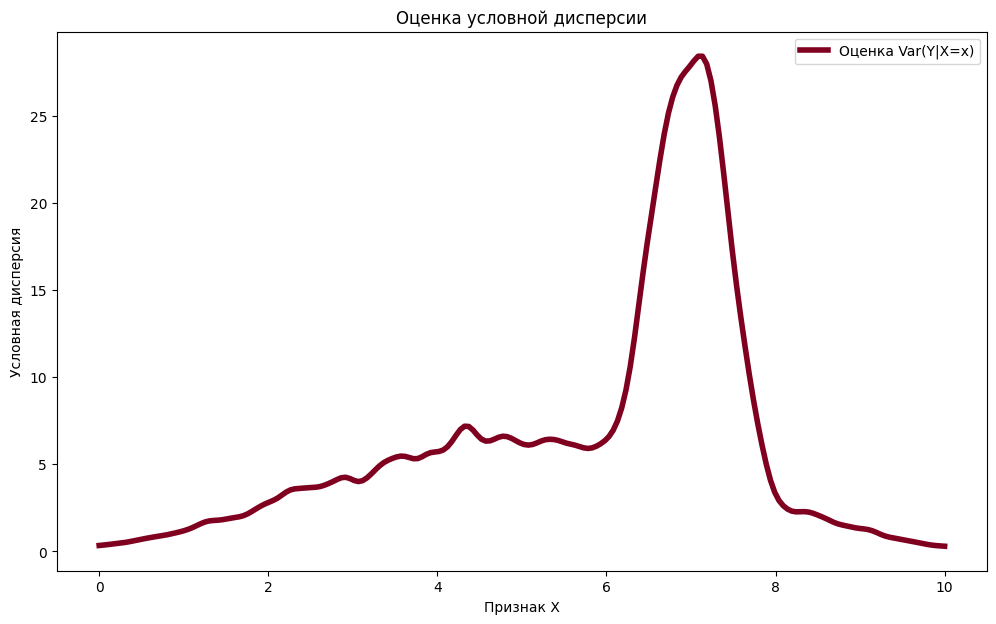

In [19]:
plt.figure(figsize=(12, 7))
plt.plot(x_grid, var_pred, color="#800020", linewidth=4, label="Оценка Var(Y|X=x)")
plt.xlabel("Признак X")
plt.ylabel("Условная дисперсия")
plt.title("Оценка условной дисперсии")
plt.legend()
plt.show()

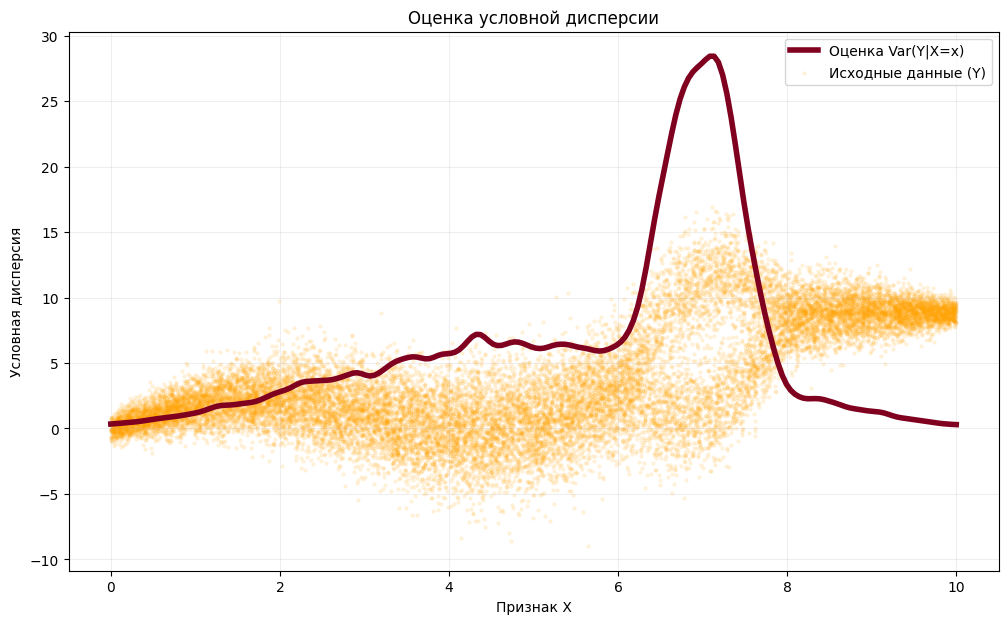

In [20]:
plt.figure(figsize=(12, 7))
plt.plot(x_grid, var_pred, color="#800020", linewidth=4, label="Оценка Var(Y|X=x)")
plt.scatter(X, Y, alpha=0.1, s=5, color="orange", label="Исходные данные (Y)")
plt.xlabel("Признак X")
plt.ylabel("Условная дисперсия")
plt.title("Оценка условной дисперсии")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### Вывод по графику условной дисперсии

Построенный график показывает оценку условной дисперсии $\mathbb{Var}(Y \mid X = x)$ в зависимости от признака $X$.

**Что видно на графике:**

- Условная дисперсия непостоянна — она **меняется с изменением $X$**;
- В области $X \in (6, 8)$ наблюдается **пик дисперсии** — это соответствует месту, где данные раздваиваются (две ветки);
- В областях с низким уровнем шума (например, $X \approx 0$ или $X \approx 10$) дисперсия **минимальна**.

**Вывод:**

Разброс таргета $Y$ существенно зависит от значения признака $X$.
Это подтверждает, что разброс неодинаков при разных $X$, и использование 
условной дисперсии $\mathbb{Var}(Y \mid X)$ вместо постоянной дисперсии оправдано.

### Проверка формулы полной дисперсии по выборке

In [21]:
mean_on_sample = np.array([gaussian_kernel_regression(xi, X, Y, h) for xi in X])
mean_sq_on_sample = np.array([gaussian_kernel_regression(xi, X, Y**2, h) for xi in X])
var_on_sample = np.maximum(mean_sq_on_sample - mean_on_sample**2, 0)

var_y = np.var(Y)
mean_cond_var = np.mean(var_on_sample)
var_cond_mean = np.var(mean_on_sample)

print(f"Var(Y) = {var_y:.4f}")
print(f"E[Var(Y|X)] = {mean_cond_var:.4f}")
print(f"Var(E[Y|X]) = {var_cond_mean:.4f}")
print(f"Сумма = {mean_cond_var + var_cond_mean:.4f}")
print(f"Формула верна? = {np.isclose(var_y, mean_cond_var + var_cond_mean, rtol=0.001)}")

Var(Y) = 17.1304
E[Var(Y|X)] = 6.1294
Var(E[Y|X]) = 10.9979
Сумма = 17.1273
Формула верна? = True


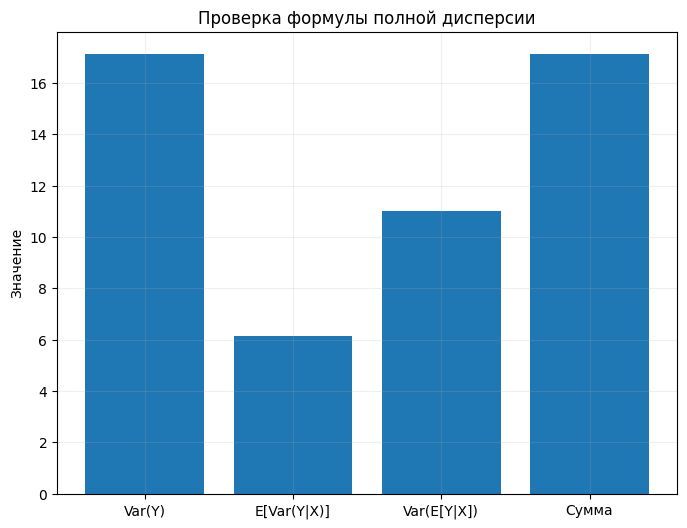

In [23]:
plt.figure(figsize=(8, 6))
values = [var_y, mean_cond_var, var_cond_mean, mean_cond_var + var_cond_mean]
labels = ["Var(Y)", "E[Var(Y|X)]", "Var(E[Y|X])", "Сумма"]
plt.bar(labels, values)
plt.title("Проверка формулы полной дисперсии")
plt.ylabel("Значение")
plt.grid(alpha=0.2)
plt.show()

### Проверка формулы полной дисперсии

На выборке объёмом $n = 20000$ с шириной окна $h = 0.1$ получены значения:

- $\mathbb{Var}(Y) = 17.1304$
- $\mathbb{E}[\mathbb{Var}(Y \mid X)] = 6.1294$
- $\mathbb{Var}[\mathbb{E}(Y \mid X)] = 10.9979$

Сумма двух последних компонент составляет $17.1273$, что отличается от общей дисперсии на $0.0031$ (относительная ошибка менее $0.02\%$).

Такое расхождение объясняется вычислительной погрешностью ядерной оценки и не противоречит теории.

**Формула полной дисперсии $\mathbb{Var}(Y) = \mathbb{E}[\mathbb{Var}(Y \mid X)] + \mathbb{Var}[\mathbb{E}(Y \mid X)]$ подтверждается.**

### Какая доля дисперсии объяснима, а какая нет
По формуле полной дисперсии:

- объяснённая часть:
$$
\mathbb{Var}\bigl(\mathbb{E}(Y \mid X)\bigr)
$$

- необъяснённая часть:
$$
\mathbb{E}\bigl[\mathbb{Var}(Y \mid X)\bigr]
$$

Доля объяснённой дисперсии:
$$
R^2 = \frac{\mathbb{Var}\bigl(\mathbb{E}(Y \mid X)\bigr)}{\mathbb{Var}(Y)}
$$

In [25]:
R2 = var_cond_mean / var_y
unexplained_share = mean_cond_var / var_y

print("R^2 =", R2)
print("Необъясненная доля =", unexplained_share)

R^2 = 0.6420117613479065
Необъясненная доля = 0.35780978127103197


**Вывод:** Признак $X$ объясняет 64% вариации таргета $Y$. 
Оставшиеся 36% приходятся на случайный шум, разрыв в данных, индивидуальные различия.
Это означает, что $X$ является важным, но не единственным фактором, 
влияющим на $Y$. Предсказания $Y$ по $X$ будут иметь ошибку, 
соответствующую необъяснённой доле дисперсии.

Опираясь на теорему о наилучшем приближении таргета по признакам (посмотрите в ноутбуе с занятия) и формулу полной дисперсии определите, какую долю дисперсии данных $Y$ оптимальная модель регрессии может "объяснить" на основе признаков $X$, а какая доля дисперсии остается необъясненной.

### Доля дисперсии, объяснённая оптимальной моделью

Из теоремы о наилучшем приближении следует, что оптимальной регрессионной функцией является

$$
f^*(X)=\mathbb{E}(Y\mid X).
$$

Минимально возможная среднеквадратичная ошибка при этом равна

$$
\mathbb{E}\bigl[(Y-\mathbb{E}(Y\mid X))^2\bigr]
=
\mathbb{E}\bigl[D(Y\mid X)\bigr].
$$

По формуле полной дисперсии

$$
D(Y)=\mathbb{E}[D(Y\mid X)] + D(\mathbb{E}(Y\mid X)).
$$

Отсюда видно, что:

- величина
  $$
  D(\mathbb{E}(Y\mid X))
  $$
  есть **объяснённая признаками $X$ часть дисперсии**;

- величина
  $$
  \mathbb{E}[D(Y\mid X)]
  $$
  есть **необъяснённая часть дисперсии**, то есть остаточный шум.

Поэтому доля дисперсии, которую может объяснить оптимальная модель, равна

$$
R^2 = \frac{D(\mathbb{E}(Y\mid X))}{D(Y)},
$$

а доля дисперсии, которая остаётся необъяснённой, равна

$$
1-R^2=\frac{\mathbb{E}[D(Y\mid X)]}{D(Y)}.
$$

Определим коэффициент детерминации как 
$$R^2 = \frac{\mathsf{D}\big[\mathsf{E}(Y|X)\big]}{\mathsf{D} Y},$$
формула для выборочного коэффициента детерминации была в ноутбуке по линейной регрессии. Покажите, что $0 \leqslant R^2 \leqslant 1$. Объясните, при каких $(X, Y)$ достигаются крайние значения $R^2 = 0$ и $R^2 = 1$ и каким случаям они соответствуют.

### Свойства коэффициента детерминации $R^2$

#### 1. Доказательство неравенства $0 \leq R^2 \leq 1$

По формуле полной дисперсии

$$
D(Y)=\mathbb{E}[D(Y\mid X)] + D(\mathbb{E}(Y\mid X)).
$$

Обе величины в правой части неотрицательны, поэтому

$$
D(\mathbb{E}(Y\mid X)) \ge 0,
\qquad
D(\mathbb{E}(Y\mid X)) \le D(Y).
$$

Делим на $D(Y)>0$ и получаем:

$$
0 \le \frac{D(\mathbb{E}(Y\mid X))}{D(Y)} \le 1.
$$

Следовательно,

$$
0 \le R^2 \le 1.
$$

---

#### 2. Когда достигается $R^2=0$

Равенство $R^2=0$ выполняется тогда и только тогда, когда

$$
D(\mathbb{E}(Y\mid X))=0.
$$

Это возможно только в случае, когда

$$
\mathbb{E}(Y\mid X)=\text{const}=\mathbb{E}Y.
$$

То есть условное среднее таргета не зависит от признаков.  
Иначе говоря, признаки $X$ не помогают предсказывать $Y$ в смысле среднего значения.

---

#### 3. Когда достигается $R^2=1$

Равенство $R^2=1$ выполняется тогда и только тогда, когда

$$
\mathbb{E}[D(Y\mid X)]=0.
$$

Так как условная дисперсия неотрицательна, это означает

$$
D(Y\mid X)=0 \quad \text{почти наверное}.
$$

Следовательно, $Y$ полностью определяется по $X$, то есть

$$
Y=f(X)
$$

для некоторой функции $f$.

Иначе говоря, в данных нет случайного шума после учёта признаков, и таргет полностью восстанавливается по $X$.

---

#### 4. Интерпретация

- $R^2=0$ — признаки не объясняют вариацию таргета;
- $R^2=1$ — таргет полностью определяется признаками;
- $0<R^2<1$ — часть дисперсии объясняется признаками, а часть остаётся шумом.

---
### Задача 3.

Пусть $\mathscr{X} = \mathbb{R}^2$ — пространство признаков, $\mathscr{Y} = \{0, 1\}$ — множество классов. Рассмотрим байесовский классификатор, в котором зададам условное распределение $X$ при условии $Y=k$ как $\mathcal{N}(a_k, \Sigma_k)$. Разделяющей поверхностью между классами $k$ и $\ell$ называется множество точек пространства признаков, для которых вероятность этих двух классов одинакова.

Приведите примеры таких параметров $a_k, \Sigma_k$ и вероятностей $\mathsf{P}(Y = k)$, при которых разделяющая поверхность является
* гиперболой;
* параболой;
* двумя параллельными прямыми;
* двумя пересекающимися прямыми.

*Примечание.* Можно подобрать выборку, посчитать оценки со страшными числами. Но еще лучше &mdash; немного подумать и привести пример с "красивыми" числами без какого-либо подбора выборки. В данном случае это довольно просто, а также позволяет лучше разобраться в параметрах многомерного нормального распределения.


Для нормального распределения плотность имеет вид

$$
f_k(x)=\frac{1}{(2\pi)^{d/2}|\Sigma_k|^{1/2}}
\exp\left(
-\frac12 (x-a_k)^\top \Sigma_k^{-1}(x-a_k)
\right).
$$

Рассмотрим байесовский классификатор для двух классов, где

$$
X \mid Y = k \sim \mathcal{N}(a_k, \Sigma_k), \quad k \in \{0,1\}.
$$

Граница между классами задаётся уравнением

$$
P(Y=0)f_0(x)=P(Y=1)f_1(x),
$$

где $f_0(x)$ и $f_1(x)$ — плотности нормальных распределений классов.

Подставим плотности и прологарифмируем. Получим:

$$
\ln P(Y=0) - \frac12 \ln |\Sigma_0|
-\frac12 (x-a_0)^\top \Sigma_0^{-1}(x-a_0)
=
\ln P(Y=1) - \frac12 \ln |\Sigma_1|
-\frac12 (x-a_1)^\top \Sigma_1^{-1}(x-a_1).
$$

После переноса всех слагаемых в одну сторону имеем уравнение вида

$$
x^\top A x + b^\top x + c = 0,
$$

где

$$
A = \Sigma_0^{-1} - \Sigma_1^{-1},
$$

а векторы $b$ и константа $c$ определяются через $a_0,a_1,\Sigma_0,\Sigma_1$ и априорные вероятности классов.

Следовательно, разделяющая граница в двумерном случае является линией второго порядка. В зависимости от параметров $a_k$, $\Sigma_k$ и априорных вероятностей $P(Y=k)$ — это может быть гипербола, парабола или вырожденные случаи — пара прямых.

In [26]:
def discriminant_diff(x_coords, y_coords, mean0, cov0, prior0, mean1, cov1, prior1):
    """
    Разность квадратичных дискриминантных функций для двух классов.
    
    Параметры:
        x_coords, y_coords: Координаты точки или сразу сетки точек на плоскости.
        mean0, mean1: Средние векторы классов.
        cov0, cov1: Ковариационные матрицы классов.
        prior0, prior1: Априорные вероятности классов.
    
    Возвращает:
        Разность дискриминантов. Ноль на границе между классами.
    """

    points = np.stack([x_coords, y_coords], axis=-1)

    cov_inv0 = np.linalg.inv(cov0)
    cov_inv1 = np.linalg.inv(cov1)

    deviation0 = points - mean0
    deviation1 = points - mean1

    dist_sq0 = np.sum((deviation0 @ cov_inv0) * deviation0, axis=-1)
    dist_sq1 = np.sum((deviation1 @ cov_inv1) * deviation1, axis=-1)

    value = (
        dist_sq0 - dist_sq1
        + np.log(np.linalg.det(cov0))
        - np.log(np.linalg.det(cov1))
        + 2 * np.log(prior1 / prior0)
    )
    return value

def plot_boundary(mean0, cov0, prior0, mean1, cov1, prior1, title,
                  xlim=(-4, 4), ylim=(-4, 4), boundary_color='#800020'):
    """
    Рисует разделяющую границу между двумя классами.
    
    Параметры:
        mean0, mean1: Средние векторы классов.
        cov0, cov1: Ковариационные матрицы классов.
        prior0, prior1: Априорные вероятности классов.
        title: Заголовок графика.
        xlim, ylim: Границы осей X и Y.
    """
    x_coords = np.linspace(xlim[0], xlim[1], 500)
    y_coords = np.linspace(ylim[0], ylim[1], 500)
    X_grid, Y_grid = np.meshgrid(x_coords, y_coords)

    Z = discriminant_diff(X_grid, Y_grid, mean0, cov0, prior0, mean1, cov1, prior1)

    plt.figure(figsize=(6, 6))
    plt.contour(X_grid, Y_grid, Z, levels=[0], linewidths=3, colors=boundary_color)
    plt.axhline(0, color="gray", linewidth=1, alpha=0.8)
    plt.axvline(0, color="gray", linewidth=1, alpha=0.8)
    plt.xlim(xlim)
    plt.ylim(ylim)
    plt.title(title)
    plt.xlabel("$x_1$")
    plt.ylabel("$x_2$")
    plt.grid(alpha=0.2)
    plt.show()

### 1. Гипербола

Выберем параметры:

$$
a_0 = \begin{pmatrix}0 \\ 0\end{pmatrix}, \quad
a_1 = \begin{pmatrix}0 \\ 0\end{pmatrix},
$$

$$
\Sigma_0 =
\begin{pmatrix}
1 & 0 \\
0 & 1
\end{pmatrix},
\quad
\Sigma_1 =
\begin{pmatrix}
0.5 & 0 \\
0 & 2
\end{pmatrix},
$$

$$
P(Y=0)=0.2, \quad P(Y=1)=0.8.
$$

Средние совпадают, поэтому линейные члены обращаются в нуль. Матрица $A = \Sigma_0^{-1} - \Sigma_1^{-1} = \operatorname{diag}(-1,\; 0.5)$ имеет собственные значения разных знаков, а свободный член $c \neq 0$ благодаря неравным априорным вероятностям. Уравнение границы имеет вид $-x_1^2 + \frac{1}{2}x_2^2 = c$ при $c \neq 0$ — гипербола.

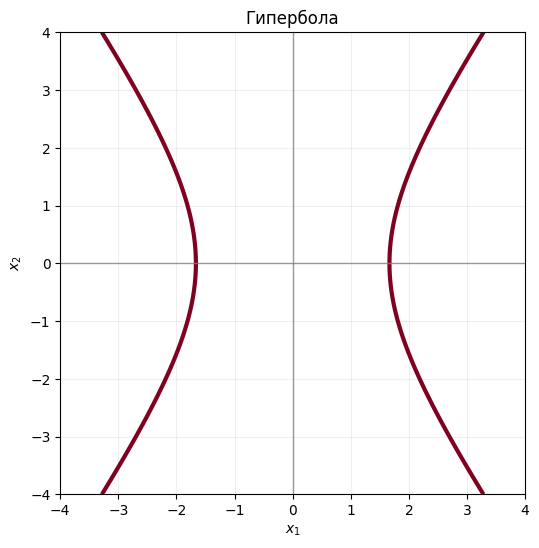

In [27]:
mean0 = np.array([0.0, 0.0])
mean1 = np.array([0.0, 0.0])

cov0 = np.eye(2)
cov1 = np.diag([0.5, 2.0])

prior0 = 0.2
prior1 = 0.8

plot_boundary(mean0, cov0, prior0, mean1, cov1, prior1, "Гипербола")

### 2. Парабола

Выберем параметры:

$$
a_0 = \begin{pmatrix}0 \\ 0\end{pmatrix}, \quad
a_1 = \begin{pmatrix}1 \\ 0\end{pmatrix},
$$

$$
\Sigma_0 =
\begin{pmatrix}
1 & 0 \\
0 & 1
\end{pmatrix},
\quad
\Sigma_1 =
\begin{pmatrix}
1 & 0 \\
0 & 0.5
\end{pmatrix},
$$

$$
P(Y=0)=0.5, \quad P(Y=1)=0.5.
$$

Матрица $A = \Sigma_0^{-1} - \Sigma_1^{-1} = \operatorname{diag}(0,\,-1)$: одно собственное значение равно нулю, поэтому квадратичный член по $x_1$ исчезает. Так как $a_0 \neq a_1$, появляется линейный член по $x_1$. Уравнение границы:

$$
-x_2^2 + 2x_1 = \mathrm{const},
$$

что является параболой.

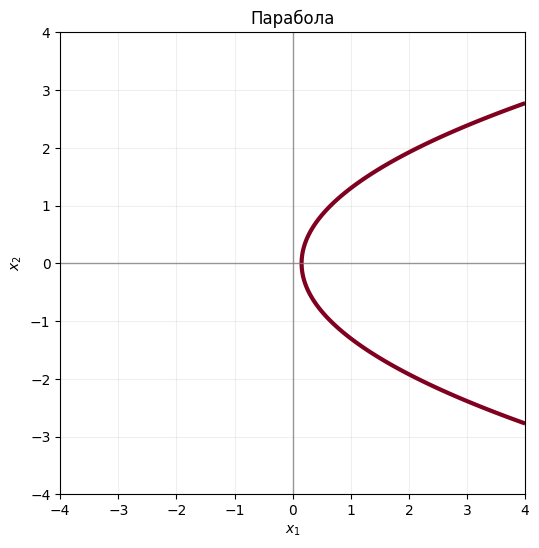

In [28]:
mean0 = np.array([0.0, 0.0])
mean1 = np.array([1.0, 0.0])

cov0 = np.eye(2)
cov1 = np.diag([1.0, 0.5])

prior0 = 0.5
prior1 = 0.5

plot_boundary(mean0, cov0, prior0, mean1, cov1, prior1, "Парабола")

### 3. Две параллельные прямые

Выберем параметры:

$$
a_0 = \begin{pmatrix}0 \\ 0\end{pmatrix}, \quad
a_1 = \begin{pmatrix}0 \\ 0\end{pmatrix},
$$

$$
\Sigma_0 =
\begin{pmatrix}
1 & 0 \\
0 & 1
\end{pmatrix},
\quad
\Sigma_1 =
\begin{pmatrix}
0.25 & 0 \\
0 & 1
\end{pmatrix},
$$

$$
P(Y=0)=0.5, \quad P(Y=1)=0.5.
$$

Так как $a_0 = a_1$ и $P(Y=0) = P(Y=1)$, линейные и константные члены обращаются в нуль. Матрица $A = \Sigma_0^{-1} - \Sigma_1^{-1} = \operatorname{diag}(-3,\; 0)$: собственное значение по $x_2$ равно нулю, квадратичный член по $x_2$ исчезает. Уравнение границы:

$$
-3x_1^2 + \ln\frac{|\Sigma_0|}{|\Sigma_1|} = 0 \implies x_1^2 = \frac{\ln 4}{3},
$$

что даёт две вертикальные параллельные прямые $x_1 = \pm\sqrt{\tfrac{\ln 4}{3}}$.

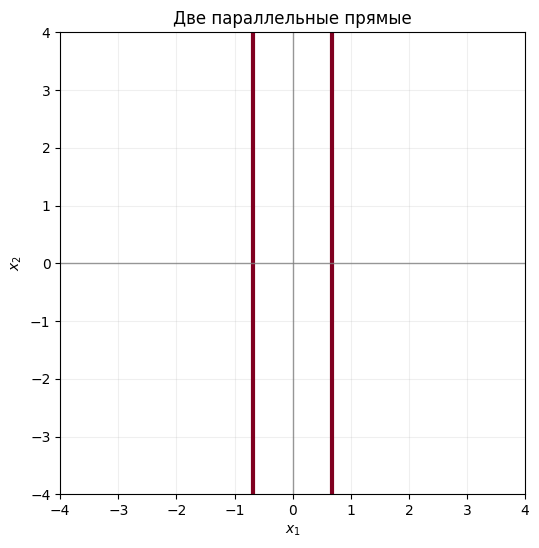

In [29]:
mean0 = np.array([0.0, 0.0])
mean1 = np.array([0.0, 0.0])

cov0 = np.eye(2)
cov1 = np.diag([0.25, 1.0])

prior0 = 0.5
prior1 = 0.5

plot_boundary(mean0, cov0, prior0, mean1, cov1, prior1, "Две параллельные прямые")

### 4. Две пересекающиеся прямые

Выберем параметры:

$$
a_0 = \begin{pmatrix}0 \\ 0\end{pmatrix}, \quad
a_1 = \begin{pmatrix}0 \\ 0\end{pmatrix},
$$

$$
\Sigma_0 =
\begin{pmatrix}
1 & 0 \\
0 & 1
\end{pmatrix},
\quad
\Sigma_1 =
\begin{pmatrix}
0.5 & 0 \\
0 & 2
\end{pmatrix},
$$

$$
P(Y=0)=0.5, \quad P(Y=1)=0.5.
$$

Так как $a_0 = a_1$ и $P(Y=0) = P(Y=1)$, линейные члены и свободный член обращаются в нуль (в отличие от случая гиперболы). Матрица $A = \Sigma_0^{-1} - \Sigma_1^{-1} = \operatorname{diag}(-1,\; 0.5)$ имеет собственные значения разных знаков, и уравнение границы принимает вид:

$$
-x_1^2 + \frac{1}{2}x_2^2 = 0,
$$

откуда $x_2 = \pm\sqrt{2}\,x_1$ — две пересекающиеся прямые, проходящие через начало координат.

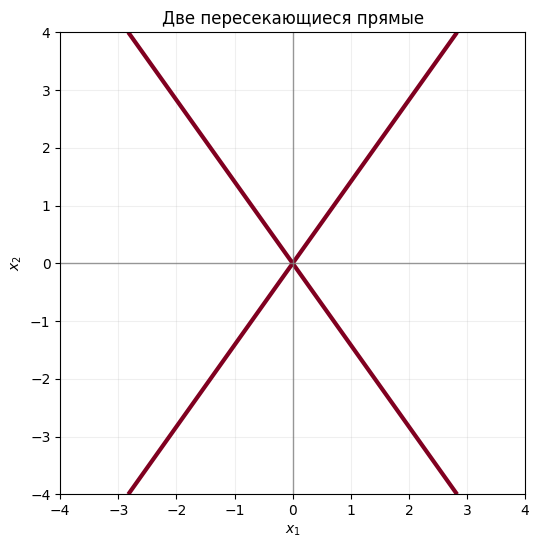

In [30]:
mean0 = np.array([0.0, 0.0])
mean1 = np.array([0.0, 0.0])

cov0 = np.eye(2)
cov1 = np.diag([0.5, 2.0])

prior0 = 0.5
prior1 = 0.5

plot_boundary(mean0, cov0, prior0, mean1, cov1, prior1, "Две пересекающиеся прямые")

**Вывод:**

Для байесовского классификатора с нормальными класс-условными распределениями разделяющая поверхность определяется уравнением второй степени. Поэтому при разных параметрах средних, ковариационных матриц и априорных вероятностей можно получить разные типы границ: гиперболу, параболу, а также вырожденные случаи — две параллельные или две пересекающиеся прямые.

---
© 2026 команда <a href="https://thetahat.ru/">ThetaHat</a> для ВвАД